# HAM10000 – Chuẩn bị dữ liệu & khởi tạo ResNet-18

Notebook này:
1. Đọc metadata + ánh xạ đường dẫn ảnh
2. Kiểm tra dữ liệu: giá trị thiếu, trùng lặp, file ảnh thiếu, phân bố nhãn
3. Mã hoá nhãn
4. Chia train / test **theo `lesion_id`** (tránh rò rỉ: một tổn thương có nhiều ảnh)
5. Tạo `Dataset` / `DataLoader`
6. Khởi tạo mô hình ResNet-18 (**chưa huấn luyện**)

## 1. Import & cấu hình

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

SEED = 42
DATA_DIR = Path("archive")
METADATA_CSV = DATA_DIR / "HAM10000_metadata.csv"
IMAGE_DIRS = [DATA_DIR / "HAM10000_images_part_1", DATA_DIR / "HAM10000_images_part_2"]
SPLIT_DIR = Path("outputs/splits")

TEST_SIZE = 0.2      # ~20% test
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0      # Windows + Jupyter: để 0 cho an toàn

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch: 2.8.0+cu126 | device: cuda | NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Đọc dữ liệu

In [2]:
df = pd.read_csv(METADATA_CSV)
print(df.shape)
df.head()

(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 547.8 KB


In [4]:
# Ánh xạ image_id -> đường dẫn file (ảnh nằm rải ở 2 thư mục)
image_paths = {p.stem: p for d in IMAGE_DIRS for p in d.glob("*.jpg")}
df["path"] = df["image_id"].map(image_paths)
print("Số file ảnh tìm thấy:", len(image_paths))

Số file ảnh tìm thấy: 10015


## 3. Kiểm tra dữ liệu

### 3.1 Giá trị thiếu (NaN và giá trị `unknown`)

In [5]:
missing = pd.DataFrame({
    "nan": df.isna().sum(),
    "unknown": (df.astype(str).apply(lambda s: s.str.lower()) == "unknown").sum(),
})
missing["tổng"] = missing.sum(axis=1)
missing["%"] = (missing["tổng"] / len(df) * 100).round(2)
missing

,nan,unknown,tổng,%
lesion_id,0,0,0,0.00
image_id,0,0,0,0.00
dx,0,0,0,0.00
dx_type,0,0,0,0.00
age,57,0,57,0.57
sex,0,57,57,0.57
localization,0,234,234,2.34
path,0,0,0,0.00


> `age` có NaN, `sex`/`localization` có giá trị `unknown`. Các cột này là **metadata phụ**, mô hình chỉ dùng ảnh + nhãn `dx`
> nên không cần loại bỏ dòng. Chỉ điền `age` bằng median để cột sạch nếu sau này muốn dùng.

In [6]:
df["age"] = df["age"].fillna(df["age"].median())
assert df["dx"].isna().sum() == 0, "Có ảnh thiếu nhãn!"
assert df["path"].isna().sum() == 0, "Có image_id không tìm thấy file ảnh!"
print("Không thiếu nhãn, mọi image_id đều có file ảnh.")

Không thiếu nhãn, mọi image_id đều có file ảnh.


### 3.2 Trùng lặp & file ảnh

In [7]:
print("Dòng trùng hoàn toàn       :", df.duplicated().sum())
print("image_id trùng             :", df["image_id"].duplicated().sum())
orphans = set(image_paths) - set(df["image_id"])
print("File ảnh không có metadata :", len(orphans))

# Mỗi lesion_id có thể có nhiều ảnh -> phải chia theo nhóm
imgs_per_lesion = df.groupby("lesion_id").size()
print("Số lesion_id               :", df["lesion_id"].nunique())
print("Số ảnh / lesion            :", imgs_per_lesion.value_counts().sort_index().to_dict())

# Mỗi lesion chỉ thuộc 1 nhãn?
assert (df.groupby("lesion_id")["dx"].nunique() == 1).all()

Dòng trùng hoàn toàn       : 0
image_id trùng             : 0
File ảnh không có metadata : 0
Số lesion_id               : 7470
Số ảnh / lesion            : {1: 5514, 2: 1423, 3: 490, 4: 34, 5: 5, 6: 4}


In [8]:
# Kiểm tra nhanh kích thước / mode trên một mẫu ảnh (không xử lý ảnh)
sample = df.sample(200, random_state=SEED)
info = [Image.open(p) for p in sample["path"]]
print(pd.Series([(im.size, im.mode) for im in info]).value_counts())

((600, 450), RGB)    200
Name: count, dtype: int64


### 3.3 Phân bố nhãn

In [9]:
DX_NAMES = {
    "nv": "Melanocytic nevi",
    "mel": "Melanoma",
    "bkl": "Benign keratosis-like lesions",
    "bcc": "Basal cell carcinoma",
    "akiec": "Actinic keratoses / Bowen's",
    "vasc": "Vascular lesions",
    "df": "Dermatofibroma",
}
counts = df["dx"].value_counts()
pd.DataFrame({"tên": counts.index.map(DX_NAMES), "số ảnh": counts,
              "%": (counts / len(df) * 100).round(2)})

,tên,số ảnh,%
dx,,,
nv,Melanocytic nevi,6705,66.95
mel,Melanoma,1113,11.11
bkl,Benign keratosis-like lesions,1099,10.97
bcc,Basal cell carcinoma,514,5.13
akiec,Actinic keratoses / Bowen's,327,3.27
vasc,Vascular lesions,142,1.42
df,Dermatofibroma,115,1.15


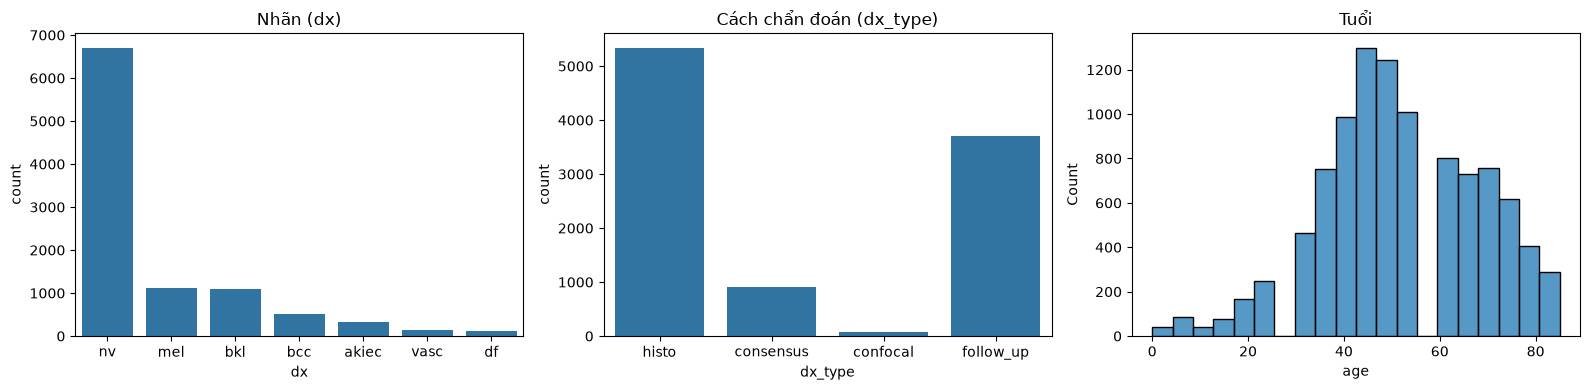

Mất cân bằng: lớp lớn nhất / nhỏ nhất = 58.3x


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="dx", order=counts.index, ax=axes[0]); axes[0].set_title("Nhãn (dx)")
sns.countplot(data=df, x="dx_type", ax=axes[1]); axes[1].set_title("Cách chẩn đoán (dx_type)")
sns.histplot(df["age"], bins=20, ax=axes[2]); axes[2].set_title("Tuổi")
plt.tight_layout(); plt.show()
print(f"Mất cân bằng: lớp lớn nhất / nhỏ nhất = {counts.max() / counts.min():.1f}x")

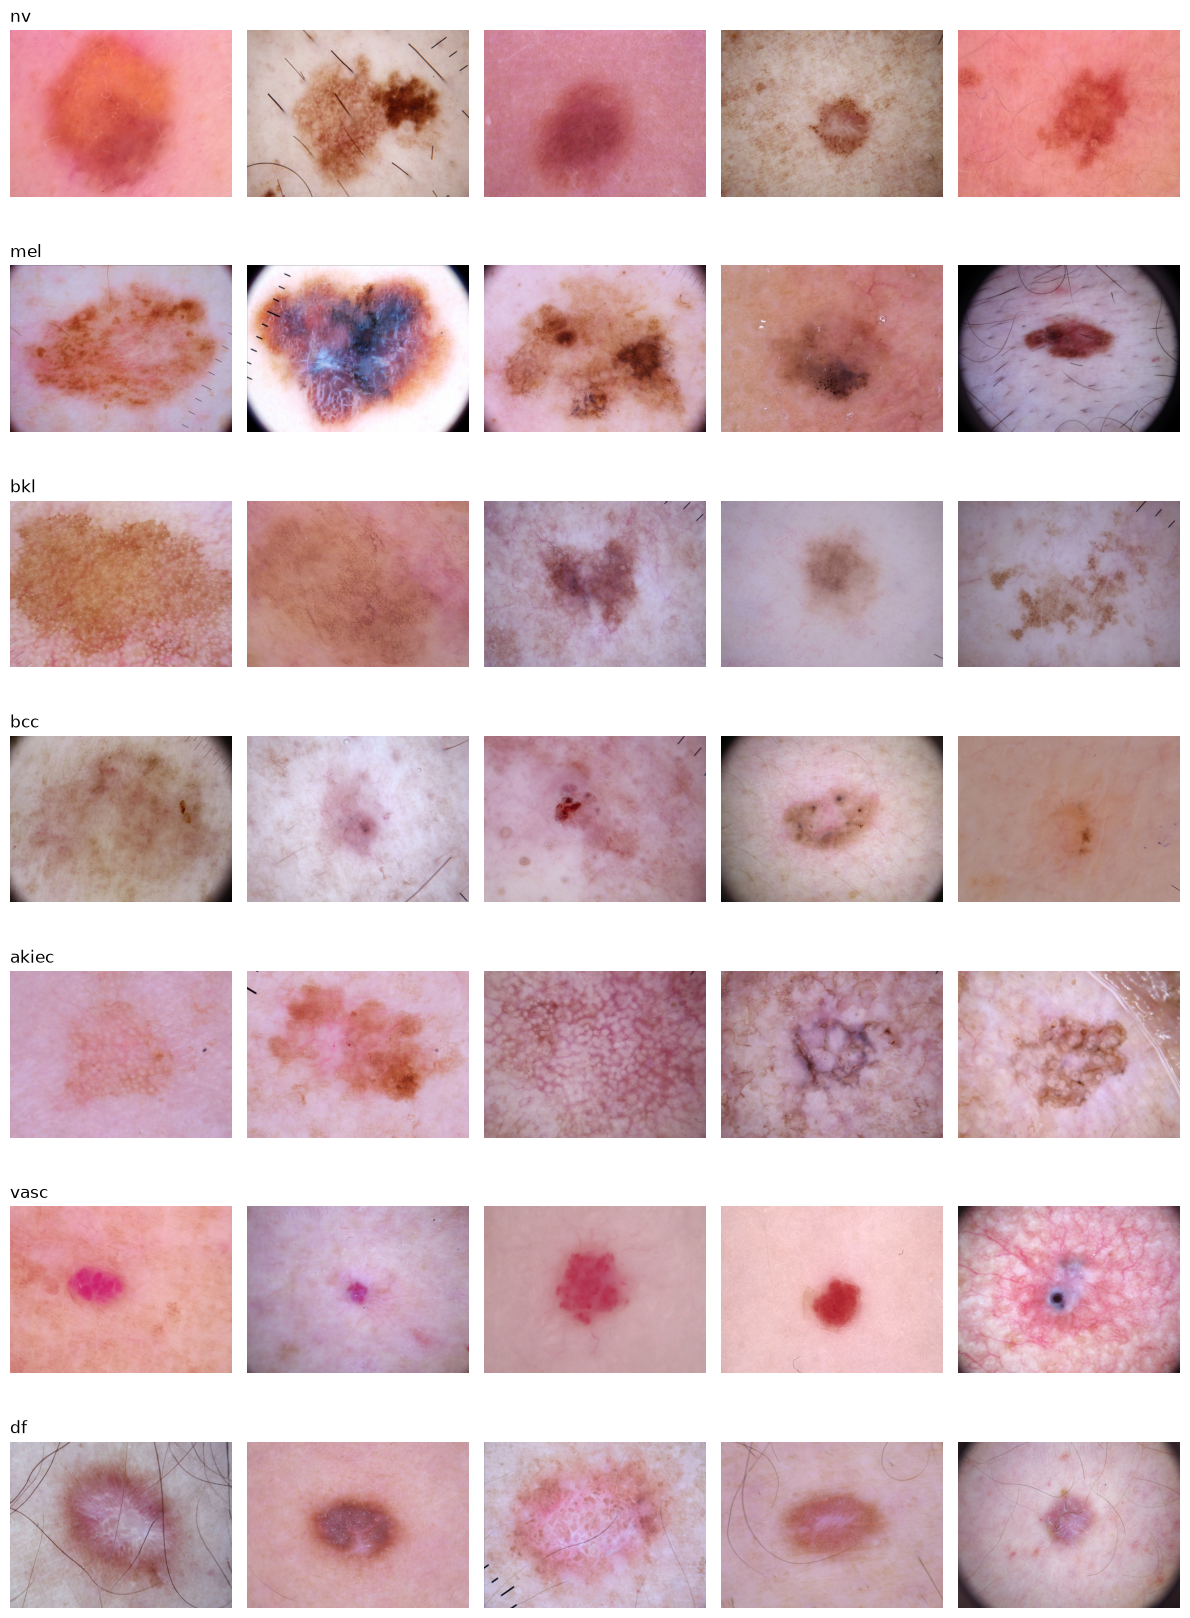

In [11]:
# Xem một vài ảnh mỗi lớp
fig, axes = plt.subplots(len(DX_NAMES), 5, figsize=(12, 2.4 * len(DX_NAMES)))
for r, dx in enumerate(counts.index):
    for c, p in enumerate(df[df["dx"] == dx].sample(5, random_state=SEED)["path"]):
        axes[r, c].imshow(Image.open(p)); axes[r, c].axis("off")
    axes[r, 0].set_title(dx, loc="left")
plt.tight_layout(); plt.show()

## 4. Mã hoá nhãn

In [12]:
CLASSES = sorted(df["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES = len(CLASSES)
df["label"] = df["dx"].map(class_to_idx)
print(class_to_idx)

{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


## 5. Chia train / test

Dùng `StratifiedGroupKFold` lấy 1 fold làm test:
- **group = `lesion_id`** → mọi ảnh của cùng 1 tổn thương nằm cùng một tập
- **stratify = `label`** → giữ tỉ lệ các lớp giữa train và test

In [13]:
n_splits = int(round(1 / TEST_SIZE))
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(df, df["label"], groups=df["lesion_id"]))
train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

assert set(train_df["lesion_id"]).isdisjoint(test_df["lesion_id"]), "Rò rỉ lesion_id!"
print(f"train: {len(train_df)} ({len(train_df)/len(df):.1%}) | test: {len(test_df)} ({len(test_df)/len(df):.1%})")

train: 8011 (80.0%) | test: 2004 (20.0%)


In [14]:
dist = pd.DataFrame({
    "train": train_df["dx"].value_counts(normalize=True),
    "test": test_df["dx"].value_counts(normalize=True),
}).mul(100).round(2)
dist["train_n"] = train_df["dx"].value_counts()
dist["test_n"] = test_df["dx"].value_counts()
dist

,train,test,train_n,test_n
dx,,,,
nv,66.96,66.92,5364,1341
mel,11.12,11.08,891,222
bkl,10.97,10.98,879,220
bcc,5.13,5.14,411,103
akiec,3.26,3.29,261,66
vasc,1.41,1.45,113,29
df,1.15,1.15,92,23


In [15]:
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
cols = ["image_id", "lesion_id", "dx", "label", "path"]
train_df[cols].to_csv(SPLIT_DIR / "train.csv", index=False)
test_df[cols].to_csv(SPLIT_DIR / "test.csv", index=False)
print("Đã lưu:", list(SPLIT_DIR.glob("*.csv")))

Đã lưu: [WindowsPath('outputs/splits/test.csv'), WindowsPath('outputs/splits/train.csv')]


## 6. Dataset & DataLoader

In [16]:
# Chuẩn hoá theo ImageNet vì dùng trọng số pretrained
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class HAM10000Dataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform=None):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

train_ds = HAM10000Dataset(train_df, train_tf)
test_ds = HAM10000Dataset(test_df, test_tf)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

x, y = train_ds[0]
print("1 mẫu:", tuple(x.shape), "label:", y, f"({idx_to_class[y]})")
print("Số batch train/test:", len(train_loader), len(test_loader))

1 mẫu: (3, 224, 224) label: 2 (bkl)
Số batch train/test: 251 63


## 7. Khởi tạo mô hình ResNet-18

In [17]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)   # 512 -> 7 lớp
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Tham số: {n_params:,} | trainable: {n_train:,}")
print(model.fc)

Tham số: 11,180,103 | trainable: 11,180,103
Linear(in_features=512, out_features=7, bias=True)


In [18]:
# Class weights để xử lý mất cân bằng nhãn (tính trên train)
class_weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"])
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
print({c: round(w, 2) for c, w in zip(CLASSES, class_weights.tolist())})

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

{'akiec': 4.38, 'bcc': 2.78, 'bkl': 1.3, 'df': 12.44, 'mel': 1.28, 'nv': 0.21, 'vasc': 10.13}


In [19]:
# Sanity check: forward 1 batch giả (không huấn luyện)
model.eval()
with torch.no_grad():
    out = model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=device))
print("Output shape:", tuple(out.shape))

Output shape: (2, 7)
